# Unfallatlas 2025: Baselines for Accident Severity

**Question:** given that an accident with personal injury happened, *how likely* is it that someone was
**killed or seriously injured**, given the road users involved, the location, the time and the road conditions?

The answer is a **probability between 0 and 1**, so we treat it as a regression on the binary target
`target = UKATEGORIE <= 2` (≈ 15.7 % of accidents). We do not regress on `UKATEGORIE` itself: its codes 1/2/3
are ordered labels, not measurements, so "2.4" has no meaning.

Baselines, from simplest to least simple:

| # | Model | Idea |
| --- | --- | --- |
| 0 | Constant | always predict the training base rate |
| 1 | Rule (EDA) | two risk groups from the EDA, each predicts its own training rate |
| 2 | Rule table | rate per combination of kind of accident × motorcycle × darkness |
| 3 | Linear regression | linear probability model, coefficients = percentage points |
| 4 | Logistic regression | the standard model for probabilities, for comparison |

All models are fitted on **train** and evaluated on **validation**. The **test** split stays untouched for the final model.
Splits come from `tiziano_splits.ipynb`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                      "grid.color": "#e6e5e1", "axes.edgecolor": "#b5b4ad"})
COLORS = {"Rule (EDA)": "#eb6834", "Rule table": "#1baf7a",
          "Linear regression": "#2a78d6", "Logistic regression": "#6250d6"}
REFERENCE = "#8a8983"

## 1. Load the splits

In [2]:
def load_split(name):
    return pd.read_csv(
        f"data/splits/{name}.csv.gz",
        dtype={"UIDENTSTLAE": str, "kreis_key": str, "gemeinde_key": str},
        parse_dates=["datetime"],
    )


train = load_split("train")
val = load_split("val")

TARGET = "target"
y_train, y_val = train[TARGET], val[TARGET]
base_rate = y_train.mean()
print(f"train: {len(train):,} rows | val: {len(val):,} rows | base rate (train): {base_rate:.2%}")

train: 191,104 rows | val: 40,951 rows | base rate (train): 15.72%


## 2. Features

The four groups from the question map to these columns:

| group | columns |
| --- | --- |
| road users | `IstRad`, `IstPKW`, `IstFuss`, `IstKrad`, `IstGkfz`, `IstSonstige`, `n_involved` |
| accident | `UART` (kind), `UTYP1` (type) |
| location | `ULAND` (state), `lon`, `lat` |
| time | `hour_sin/cos`, `month_sin/cos`, `is_weekend` |
| road conditions | `ULICHTVERH` (light), `IstStrassenzustand` (surface) |

The high-cardinality district/municipality keys are left out of the baselines: they need target encoding, which is a step for the next model iteration.

Codes without a meaningful order are **one-hot encoded**; continuous columns are **standardised**. Both steps
are fitted inside a pipeline, so they learn from the training data only.

In [3]:
CATEGORICAL = ["ULAND", "UART", "UTYP1", "ULICHTVERH", "IstStrassenzustand"]
BINARY = ["IstRad", "IstPKW", "IstFuss", "IstKrad", "IstGkfz", "IstSonstige", "is_weekend"]
NUMERIC = ["hour_sin", "hour_cos", "month_sin", "month_cos", "n_involved", "lon", "lat"]
FEATURES = CATEGORICAL + BINARY + NUMERIC

X_train, X_val = train[FEATURES], val[FEATURES]


def make_preprocessor():
    return ColumnTransformer([
        # drop="first" avoids perfectly collinear dummies, which keeps linear coefficients interpretable
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CATEGORICAL),
        ("bin", "passthrough", BINARY),
        ("num", StandardScaler(), NUMERIC),
    ], verbose_feature_names_out=False)

## 3. Rule-based baselines

Yes, a rule can be a regression baseline, as long as it outputs a probability. Each rule assigns an accident to a group,
and the prediction is the **share of severe accidents in that group in the training data**. This is still "fitting", but only
of group averages, so it is transparent and hard to beat by accident.

* **Constant:** one group, everything gets the base rate.
* **Rule (EDA):** "high risk" if a motorcycle, pedestrian or goods vehicle is involved, or the accident was a
  collision with oncoming traffic (`UART = 4`) or the vehicle left the carriageway (`UART` 8/9). These stood out in the EDA.
* **Rule table:** a lookup table over kind of accident (10) × motorcycle involved (2) × darkness (2) = 40 cells.
  Cells with fewer than 30 training accidents fall back to the base rate.

In [4]:
class GroupRateModel:
    """Predicts the training share of positives in the group a row belongs to."""

    def __init__(self, group_fn, min_count=30):
        self.group_fn = group_fn
        self.min_count = min_count

    def fit(self, X, y):
        stats = y.groupby(self.group_fn(X)).agg(["mean", "size"])
        self.base_rate_ = y.mean()
        self.rates_ = stats.loc[stats["size"] >= self.min_count, "mean"]
        self.table_ = stats
        return self

    def predict(self, X):
        groups = self.group_fn(X)
        return groups.map(self.rates_).fillna(self.base_rate_).to_numpy(dtype=float)


def constant_group(X):
    return pd.Series("all", index=X.index)


def eda_rule(X):
    high_risk = (
        X[["IstKrad", "IstFuss", "IstGkfz"]].any(axis=1)
        | X["UART"].isin([4, 8, 9])
    )
    return high_risk.map({True: "high risk", False: "other"})


def rule_table(X):
    return (
        "UART=" + X["UART"].astype(str)
        + " | moto=" + X["IstKrad"].astype(str)
        + " | dark=" + (X["ULICHTVERH"] == 2).astype(int).astype(str)
    )


constant = GroupRateModel(constant_group).fit(X_train, y_train)
rule_eda = GroupRateModel(eda_rule).fit(X_train, y_train)
rule_tab = GroupRateModel(rule_table).fit(X_train, y_train)

rule_eda.table_.rename(columns={"mean": "share severe", "size": "train accidents"})

,share severe,train accidents
high risk,0.223045,78455
other,0.111284,112649


In [5]:
(rule_tab.table_.sort_values("mean", ascending=False)
 .rename(columns={"mean": "share severe", "size": "train accidents"})
 .head(10))

,share severe,train accidents
UART=4 | moto=1 | dark=0,0.416569,1702
UART=8 | moto=1 | dark=0,0.387005,2801
UART=9 | moto=1 | dark=1,0.380753,239
UART=9 | moto=1 | dark=0,0.374095,1243
UART=4 | moto=1 | dark=1,0.351598,219
UART=8 | moto=1 | dark=1,0.346774,372
UART=7 | moto=1 | dark=0,0.277567,263
UART=7 | moto=1 | dark=1,0.272727,165
UART=6 | moto=1 | dark=1,0.271186,59
UART=5 | moto=1 | dark=0,0.268447,5543


## 4. Linear and logistic regression

**Linear regression** on a 0/1 target estimates the probability directly. Its weakness is that nothing keeps the
prediction inside [0, 1]; we count how often that happens and clip for the probability metrics.

**Logistic regression** passes the same linear score through a sigmoid, so predictions are always valid probabilities.

In [6]:
linreg = make_pipeline(make_preprocessor(), LinearRegression()).fit(X_train, y_train)
logreg = make_pipeline(make_preprocessor(), LogisticRegression(max_iter=2000)).fit(X_train, y_train)

raw_linear = linreg.predict(X_val)
print(f"linear regression predictions outside [0, 1]: {((raw_linear < 0) | (raw_linear > 1)).mean():.2%} "
      f"(min {raw_linear.min():.3f}, max {raw_linear.max():.3f})")

linear regression predictions outside [0, 1]: 0.26% (min -0.054, max 0.494)


## 5. Evaluation

The models output probabilities, so we evaluate them in three ways:

1. **Probability quality** (the regression view)
   * **Brier score** = mean squared error between the predicted probability and the 0/1 outcome. Lower is better.
   * **Brier skill score** = improvement over the constant model (0 = no better, 1 = perfect).
   * **Log loss**: punishes confident wrong predictions harder.
2. **Ranking:** does a severe accident get a higher score than a slight one?
   * **ROC-AUC** (0.5 = random) and **average precision / PR-AUC** (random = base rate ≈ 0.157). PR-AUC is the more honest one with imbalanced classes.
3. **Decisions:** if we flag accidents above a threshold, how good are the flags?
   * Precision, recall and F1 for the severe class. The threshold maximising F1 is chosen on the **training** predictions and then applied to validation.

In [7]:
models = {
    "Constant": constant,
    "Rule (EDA)": rule_eda,
    "Rule table": rule_tab,
    "Linear regression": linreg,
    "Logistic regression": logreg,
}


def predict_proba(model, X):
    if isinstance(model, GroupRateModel):
        return model.predict(X)
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return np.clip(model.predict(X), 0, 1)


def best_f1_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return thresholds[np.argmax(f1[:-1])]


brier_constant = brier_score_loss(y_val, predict_proba(constant, X_val))
pred_val, rows = {}, []
for name, model in models.items():
    p_train, p_val = predict_proba(model, X_train), predict_proba(model, X_val)
    pred_val[name] = p_val
    row = {
        "Brier": brier_score_loss(y_val, p_val),
        "Brier skill": 1 - brier_score_loss(y_val, p_val) / brier_constant,
        "log loss": log_loss(y_val, np.clip(p_val, 1e-6, 1 - 1e-6)),
        "ROC-AUC": roc_auc_score(y_val, p_val),
        "PR-AUC": average_precision_score(y_val, p_val),
    }
    if name != "Constant":
        threshold = best_f1_threshold(y_train, p_train)
        flags = p_val >= threshold
        row |= {
            "threshold": threshold,
            "% flagged": flags.mean() * 100,
            "precision": precision_score(y_val, flags),
            "recall": recall_score(y_val, flags),
            "F1": f1_score(y_val, flags),
        }
    rows.append(pd.Series(row, name=name))

results = pd.DataFrame(rows)
results.round(4)

,Brier,Brier skill,log loss,ROC-AUC,PR-AUC,threshold,% flagged,precision,recall,F1
Constant,0.1325,0.0000,0.4349,0.5000,0.1572,NaN,NaN,NaN,NaN,NaN
Rule (EDA),0.1293,0.0236,0.4234,0.6036,0.1964,0.2230,40.6803,0.2246,0.5814,0.3241
Rule table,0.1272,0.0396,0.4157,0.6489,0.2440,0.1680,48.7412,0.2188,0.6785,0.3309
Linear regression,0.1262,0.0476,0.4120,0.6674,0.2647,0.1707,40.2603,0.2369,0.6067,0.3407
Logistic regression,0.1263,0.0469,0.4117,0.6672,0.2642,0.1628,39.3519,0.2392,0.5988,0.3418


**Reading the table.** Every model beats the constant baseline, but only modestly:

* **Linear and logistic regression are practically tied** (ROC-AUC 0.667, PR-AUC 0.265 vs. 0.157 for random, Brier skill ≈ 0.05). For this task, linear regression loses nothing against the "proper" probability model. It produces invalid probabilities for only 0.26 % of accidents, and its highest prediction is 0.49.
* **The 40-cell rule table already gets most of the way** (ROC-AUC 0.649, PR-AUC 0.244). Three facts (kind of accident, motorcycle, darkness) carry most of the signal that the linear models find in all features.
* **The two-group EDA rule** separates 22 % vs. 11 % severe. It is better than nothing, but coarse.
* **As a yes/no flag** (threshold chosen on train), the best models flag ~40 % of accidents and catch ~60 % of the severe ones, with a precision of only ~24 % (F1 ≈ 0.34). That is too blunt for a decision tool, but it is the score to beat.

The scores are modest because the outcome mostly depends on things that are not in the data: speed, seatbelt and helmet use, age of the people involved, and vehicle type and mass.

### Calibration and precision–recall curves

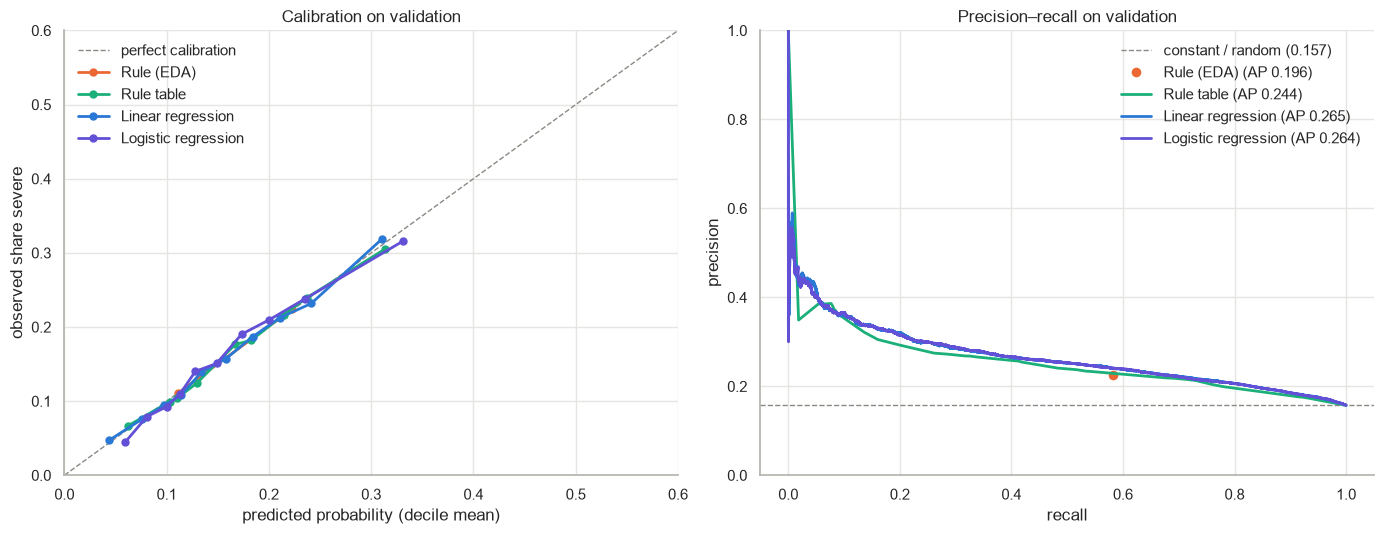

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
ax.plot([0, 0.6], [0, 0.6], color=REFERENCE, ls="--", lw=1, label="perfect calibration")
for name, color in COLORS.items():
    frac_pos, mean_pred = calibration_curve(y_val, pred_val[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", ms=5, lw=2, color=color, label=name)
ax.set(xlabel="predicted probability (decile mean)", ylabel="observed share severe",
       title="Calibration on validation", xlim=(0, 0.6), ylim=(0, 0.6))
ax.legend(frameon=False)

ax = axes[1]
ax.axhline(y_val.mean(), color=REFERENCE, ls="--", lw=1, label=f"constant / random ({y_val.mean():.3f})")
for name, color in COLORS.items():
    ap = average_precision_score(y_val, pred_val[name])
    if name == "Rule (EDA)":
        # only two distinct scores, so it is a single operating point, not a curve
        ax.plot(results.loc[name, "recall"], results.loc[name, "precision"], "o", ms=9, color=color,
                markeredgecolor="white", markeredgewidth=2, label=f"{name} (AP {ap:.3f})")
        continue
    precision, recall, _ = precision_recall_curve(y_val, pred_val[name])
    ax.plot(recall, precision, lw=2, color=color, label=f"{name} (AP {ap:.3f})")
ax.set(xlabel="recall", ylabel="precision", title="Precision–recall on validation", ylim=(0, 1))
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

**Calibration (left):** all models sit on the diagonal. When they say 30 %, about 30 % of those accidents are severe, so the probabilities can be taken at face value. Note how narrow the predicted range is (≈ 0.05–0.33): no model is ever confident that an accident will be severe.

**Precision–recall (right):** linear and logistic regression overlap completely. Above about 10 % recall, precision stays between 0.25 and 0.35. The baselines identify *riskier groups*, not individual severe accidents.

### Lift by decile

A stakeholder-friendly view: sort validation accidents by predicted risk, cut into ten equal groups,
and compare the observed share of severe accidents per group with the base rate.

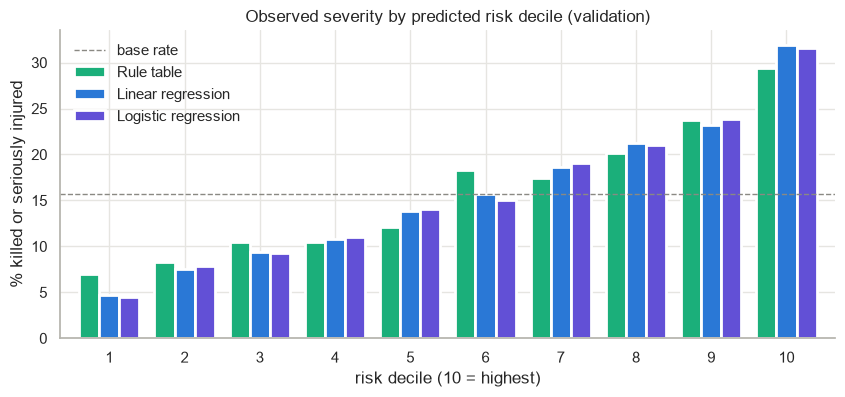

risk decile (10 = highest),1,2,3,4,5,6,7,8,9,10
Rule table,7.0,8.3,10.4,10.4,12.1,18.3,17.4,20.1,23.7,29.4
Linear regression,4.7,7.6,9.4,10.8,13.9,15.8,18.7,21.2,23.2,31.9
Logistic regression,4.5,7.9,9.3,11.0,14.0,15.1,19.0,21.0,23.8,31.6


In [9]:
lift = pd.DataFrame({
    name: pd.Series(y_val.to_numpy()).groupby(pd.qcut(pd.Series(pred_val[name]).rank(method="first"),
                                                      10, labels=range(1, 11))).mean()
    for name in ["Rule table", "Linear regression", "Logistic regression"]
}) * 100
lift.index.name = "risk decile (10 = highest)"

fig, ax = plt.subplots(figsize=(10, 4))
lift.plot.bar(ax=ax, color=[COLORS[c] for c in lift.columns], width=0.8, edgecolor="white", linewidth=2)
ax.axhline(y_val.mean() * 100, color=REFERENCE, ls="--", lw=1, label="base rate")
ax.set(ylabel="% killed or seriously injured", title="Observed severity by predicted risk decile (validation)")
ax.tick_params(axis="x", rotation=0)
ax.legend(frameon=False)
plt.show()
lift.round(1).T

Ranked by predicted risk, the **top 10 % of accidents are about twice as likely to be severe** as average (~32 % vs. 15.7 %), and the bottom 10 % about a third as likely (~5 %). This is the most useful way to present the baseline, for example as "which accident situations should prevention campaigns target first".

## 6. What the linear model learned

A strength of linear regression on a 0/1 target: each coefficient is the change in the **probability of a severe
outcome, in percentage points**, holding everything else fixed (one-hot columns compare with the dropped reference
category; standardised columns are per standard deviation).

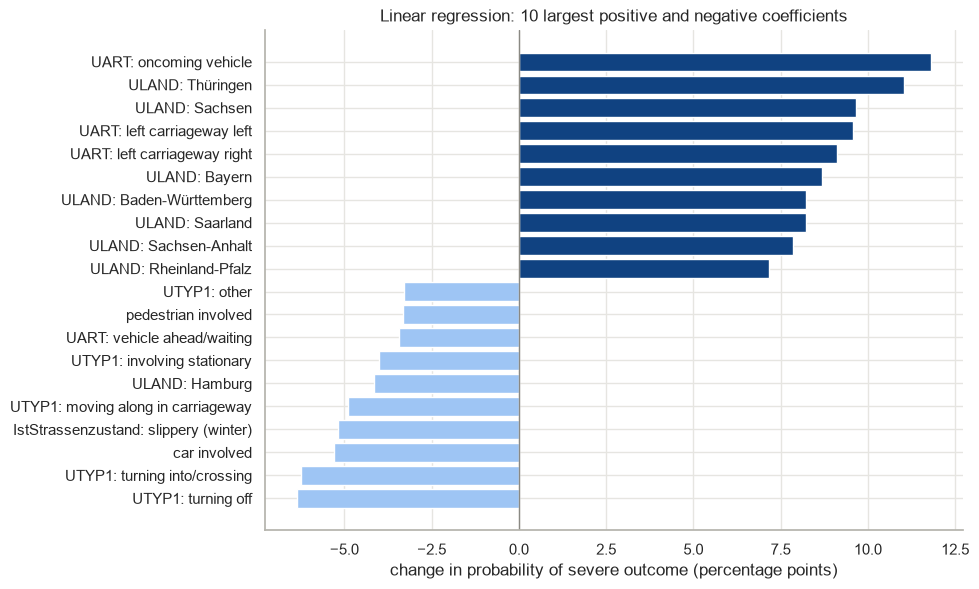

intercept: 14.9 %


In [10]:
LABELS = {
    "ULAND": {2: "Hamburg", 3: "Niedersachsen", 4: "Bremen", 5: "Nordrhein-Westfalen", 6: "Hessen",
              7: "Rheinland-Pfalz", 8: "Baden-Württemberg", 9: "Bayern", 10: "Saarland", 11: "Berlin",
              12: "Brandenburg", 13: "Mecklenburg-Vorpommern", 14: "Sachsen", 15: "Sachsen-Anhalt", 16: "Thüringen"},
    "UART": {1: "starting/stopping/stationary vehicle", 2: "vehicle ahead/waiting", 3: "lateral, same direction",
             4: "oncoming vehicle", 5: "turning/crossing vehicle", 6: "vehicle-pedestrian",
             7: "obstacle on carriageway", 8: "left carriageway right", 9: "left carriageway left"},
    "UTYP1": {2: "turning off", 3: "turning into/crossing", 4: "pedestrian crossing", 5: "involving stationary",
              6: "moving along in carriageway", 7: "other"},
    "ULICHTVERH": {1: "twilight", 2: "darkness"},
    "IstStrassenzustand": {1: "wet/damp", 2: "slippery (winter)"},
}
FLAG_NAMES = {"IstRad": "bicycle involved", "IstPKW": "car involved", "IstFuss": "pedestrian involved",
              "IstKrad": "motorcycle involved", "IstGkfz": "goods vehicle involved", "IstSonstige": "other vehicle involved"}


def readable(feature):
    column, _, code = feature.rpartition("_")
    if column in LABELS:
        return f"{column}: {LABELS[column][int(code)]}"
    return FLAG_NAMES.get(feature, feature)


coef = pd.Series(
    linreg[-1].coef_ * 100,
    index=[readable(f) for f in linreg[0].get_feature_names_out()],
    name="percentage points",
)
top = pd.concat([coef.nlargest(10), coef.nsmallest(10)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top.index, top.values, color=np.where(top > 0, "#104281", "#9ec5f4"))
ax.axvline(0, color=REFERENCE, lw=1)
ax.set(xlabel="change in probability of severe outcome (percentage points)",
       title="Linear regression: 10 largest positive and negative coefficients")
plt.show()
print(f"intercept: {linreg[-1].intercept_ * 100:.1f} %")

**How to read it:** each bar is the change in the probability of a severe outcome, in percentage points, compared with the reference category: Schleswig-Holstein for states, "other kind" for kind of accident, driving accident for type, daylight, and dry road. The intercept (14.9 %) is the baseline probability before these adjustments.

* **Collisions with oncoming traffic (+12 pp) and leaving the carriageway (+9–10 pp)** raise the risk most, in line with the EDA.
* **State effects are large** (Thüringen +11 pp, Sachsen +10 pp). These are probably proxies for rural roads and higher speeds. They are also entangled with `lon`/`lat`, so treat their exact size with care.
* **Some signs look odd but are conditional:** "pedestrian involved" is *negative* because the pedestrian effect is already captured by the vehicle-pedestrian kind of accident. "Slippery (winter)" is negative because people drive more slowly on icy roads. Correlated features share credit, so a coefficient is not a stand-alone causal effect.

## 7. Summary

| | Brier skill | ROC-AUC | PR-AUC | F1 (val) |
| --- | --- | --- | --- | --- |
| Constant (15.7 %) | 0 | 0.50 | 0.157 | – |
| Rule (EDA) | 0.024 | 0.60 | 0.196 | 0.32 |
| Rule table | 0.040 | 0.65 | 0.244 | 0.33 |
| **Linear regression** | **0.048** | **0.667** | **0.265** | **0.34** |
| Logistic regression | 0.047 | 0.667 | 0.264 | 0.34 |

* **Can a rule be a regression baseline?** Yes: assign groups and predict each group's training rate. A 40-cell rule table is surprisingly close to the linear models, which makes it a strong, explainable reference.
* **Linear regression is a valid baseline here.** Its probabilities are well calibrated, rarely out of range, as good as logistic regression, and its coefficients read directly as percentage points.
* **The scores to beat:** PR-AUC 0.265, ROC-AUC 0.667, Brier 0.126 on validation.
* The scores are modest because the outcome mostly depends on things that are not in the data: speed, seatbelt and helmet use, age of the people involved, and vehicle type and mass.

**Next steps:** tree-based models (random forest, gradient boosting) that can learn interactions such as motorcycle × rural × night; target-encoded district/municipality keys; an urban/rural indicator; cross-validated hyperparameter tuning on train; then error analysis on validation. Evaluate the test set only once, for the final model.